### **NAMA : SULFIANI**
### **NIM : H061241033**
### **MATKUL : KECERDASAN ARTIFISIAL GEOFISIKA**

# Pemetaan Persebaran Gempa dibeberapa wilayah di Indonesia



## 1. Sumber dan batasan data

File `data_gempa_indonesia.geojson` memuat **22 kejadian terpilih** dari laman katalog USGS. Ini adalah subset untuk latihan pemetaan, bukan katalog lengkap semua gempa yang terjadi di Indonesia. Setiap fitur memiliki tautan sumber `source_url`.

GeoJSON menyimpan titik dengan urutan koordinat `[longitude, latitude, depth]`. Untuk pemetaan, bujur dan lintang menjadi posisi episenter, sementara nilai kedalaman disimpan sebagai atribut.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.basemap import Basemap
from IPython.display import display

ROOT = Path.cwd()
GEOJSON_FILE = ROOT / "data_gempa_indonesia.geojson"
OUT_DIR = ROOT / "hasil"
OUT_DIR.mkdir(exist_ok=True)

with GEOJSON_FILE.open(encoding="utf-8") as f:
    geojson = json.load(f)

rows = []
for feature in geojson["features"]:
    coords = feature["geometry"]["coordinates"]
    props = feature.get("properties", {}).copy()
    props["event_id"] = feature.get("id", props.get("event_id", ""))
    props["lon"] = coords[0]
    props["lat"] = coords[1]
    props["depth_km"] = props.get("depth_km", coords[2] if len(coords) > 2 else np.nan)
    rows.append(props)

df = pd.DataFrame(rows)
df["time_utc"] = pd.to_datetime(df["time_utc"], utc=True, errors="coerce")
for col in ["mag", "lat", "lon", "depth_km"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["year"] = df["time_utc"].dt.year
df["depth_class"] = pd.cut(
    df["depth_km"], bins=[-0.001, 70, 300, np.inf],
    labels=["Dangkal (<70 km)", "Menengah (70–300 km)", "Dalam (>300 km)"],
    include_lowest=True
).astype(str)

df = df.dropna(subset=["mag", "lat", "lon", "depth_km"]).sort_values("time_utc").reset_index(drop=True)
print(f"Jumlah fitur GeoJSON yang dianalisis: {len(df)}")
print(f"Rentang tahun: {df['year'].min():.0f}–{df['year'].max():.0f}")
print(f"Rentang magnitudo: {df['mag'].min():.1f}–{df['mag'].max():.1f}")
print(f"Rentang kedalaman: {df['depth_km'].min():.1f}–{df['depth_km'].max():.1f} km")
display(df[["time_utc", "place", "mag", "lat", "lon", "depth_km", "depth_class"]].head(8))

Jumlah fitur GeoJSON yang dianalisis: 22
Rentang tahun: 1932–2023
Rentang magnitudo: 4.1–9.1
Rentang kedalaman: 10.0–597.0 km


,time_utc,place,mag,lat,lon,depth_km,depth_class
0,1932-03-26 09:52:27+00:00,"71 km SSE of Ambon, Indonesia",6.5,-4.324,128.328,35.0,Dangkal (<70 km)
1,1984-01-08 15:24:13+00:00,"18 km SSW of Mamuju, Indonesia",7.0,-2.823,118.806,33.0,Dangkal (<70 km)
2,1996-01-01 08:05:10+00:00,"181 km N of Palu, Indonesia",7.9,0.729,119.931,24.0,Dangkal (<70 km)
3,1996-03-25 18:20:33+00:00,"Sulawesi, Indonesia",4.1,-3.723,122.437,33.0,Dangkal (<70 km)
4,2004-02-07 02:42:35+00:00,"Near the south coast of Papua, Indonesia",7.3,-4.003,135.023,10.0,Dangkal (<70 km)
5,2004-12-26 00:58:53+00:00,"Sumatra-Andaman Islands, Indonesia",9.1,3.295,95.982,30.0,Dangkal (<70 km)
6,2005-03-28 16:09:36+00:00,"78 km WSW of Singkil, Indonesia (Nias region)",8.6,2.085,97.108,30.0,Dangkal (<70 km)
7,2009-09-30 10:16:09+00:00,"30 km WSW of Pariaman, Indonesia",7.6,-0.720,99.867,81.0,Menengah (70–300 km)


## 2. Peta persebaran

Basemap memberikan garis pantai dan konteks wilayah Indonesia. Titik yang besar menunjukkan magnitudo lebih besar. Warna mengikuti nilai kedalaman; lihat colorbar di sebelah kanan peta.

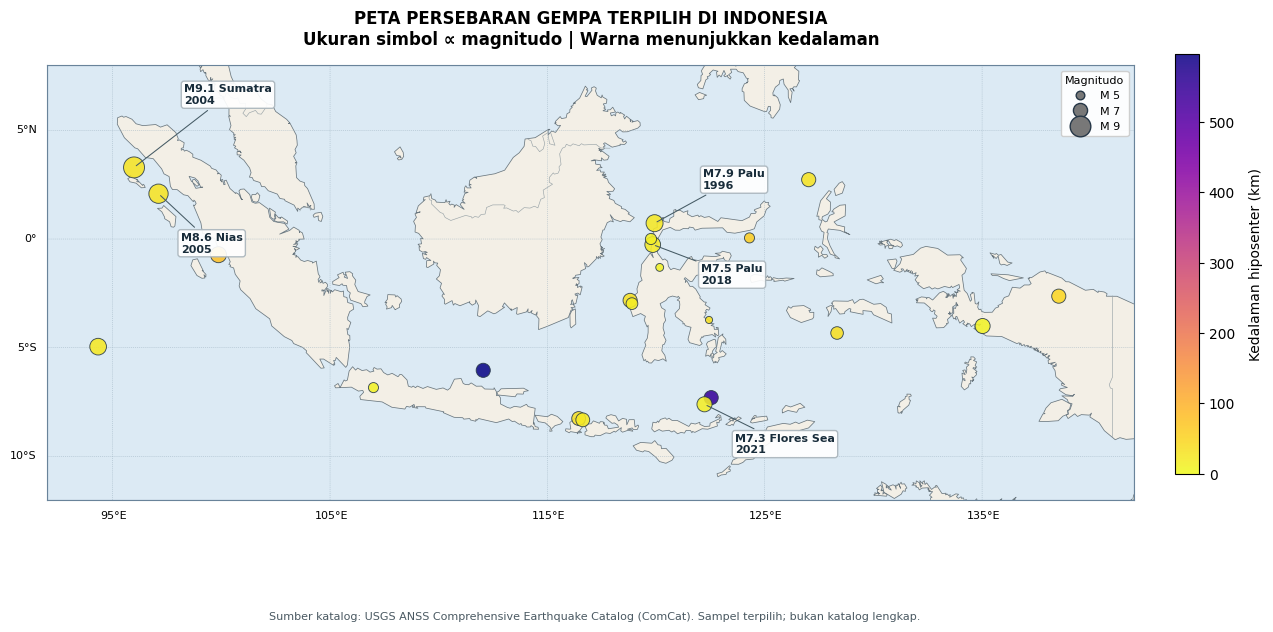

In [2]:
fig, ax = plt.subplots(figsize=(13.5, 7.5))
bm = Basemap(
    projection="cyl", llcrnrlon=92, urcrnrlon=142,
    llcrnrlat=-12, urcrnrlat=8, resolution="l", ax=ax
)
bm.drawmapboundary(fill_color="#dceaf4", linewidth=0.8, color="#69839a")
bm.fillcontinents(color="#f3efe6", lake_color="#dceaf4", zorder=1)
bm.drawcoastlines(linewidth=0.55, color="#6a777f", zorder=2)
bm.drawcountries(linewidth=0.45, color="#9aa4a8", zorder=2)
bm.drawparallels(range(-10, 10, 5), labels=[1,0,0,0], linewidth=0.35,
                 dashes=[2,2], color="#9eb3c1", fontsize=8)
bm.drawmeridians(range(95, 145, 10), labels=[0,0,0,1], linewidth=0.35,
                 dashes=[2,2], color="#9eb3c1", fontsize=8)

sizes = 24 + (df["mag"].clip(lower=3.5) - 3.5) ** 2 * 6.5
sc = bm.scatter(
    df["lon"], df["lat"], latlon=True, s=sizes,
    c=df["depth_km"], cmap="plasma_r", vmin=0,
    vmax=max(100.0, float(df["depth_km"].max())),
    alpha=0.88, edgecolors="#263747", linewidths=0.65, zorder=5
)

# Colorbar diletakkan pada axes sendiri agar area peta tetap proporsional.
cax = fig.add_axes([0.91, 0.23, 0.018, 0.56])
cbar = fig.colorbar(sc, cax=cax)
cbar.set_label("Kedalaman hiposenter (km)", rotation=90, labelpad=10)

# Label hanya untuk beberapa kejadian bermagnitudo terbesar agar peta tetap terbaca.
labels = [
    ("official20041226005853450_30", "M9.1 Sumatra\n2004", (36, 46)),
    ("official20050328160936530_30", "M8.6 Nias\n2005", (16, -42)),
    ("usp00079zv", "M7.9 Palu\n1996", (35, 25)),
    ("us1000h3p4", "M7.5 Palu\n2018", (35, -28)),
    ("us6000gc2a", "M7.3 Flores Sea\n2021", (22, -35)),
]
for event_id, label, offset in labels:
    match = df.loc[df["event_id"].astype(str) == event_id]
    if not match.empty:
        r = match.iloc[0]
        ax.annotate(
            label, xy=(r["lon"], r["lat"]), xytext=offset,
            textcoords="offset points", fontsize=8, fontweight="bold", color="#182c3a",
            arrowprops={"arrowstyle":"-", "color":"#455a64", "lw":0.75},
            bbox={"boxstyle":"round,pad=0.25", "fc":"white", "ec":"#aab5bc", "alpha":0.92},
            zorder=7
        )

# Legenda ukuran simbol: ukuran lingkaran menjelaskan skala magnitudo.
mag_legend = [5, 7, 9]
handles = [Line2D([0], [0], marker="o", linestyle="", color="w",
                  markerfacecolor="#787878", markeredgecolor="#263747",
                  markersize=np.sqrt(24 + (m - 3.5) ** 2 * 6.5), label=f"M {m}")
           for m in mag_legend]
ax.legend(handles=handles, title="Magnitudo", loc="upper right", fontsize=8,
          title_fontsize=8, frameon=True, framealpha=0.92)
ax.set_title(
    "PETA PERSEBARAN GEMPA TERPILIH DI INDONESIA\nUkuran simbol ∝ magnitudo | Warna menunjukkan kedalaman",
    pad=15, fontweight="bold"
)
fig.subplots_adjust(left=0.075, right=0.88, top=0.85, bottom=0.12)
fig.text(0.48, 0.035,
         "Sumber katalog: USGS ANSS Comprehensive Earthquake Catalog (ComCat). Sampel terpilih; bukan katalog lengkap.",
         ha="center", fontsize=8, color="#4a5962")
fig.savefig(OUT_DIR / "peta_persebaran_gempa_indonesia.png", dpi=220, bbox_inches="tight", facecolor="white")
fig.savefig(OUT_DIR / "peta_persebaran_gempa_indonesia.pdf", bbox_inches="tight", facecolor="white")
plt.show()

## 3. Ringkasan statistik

Tabel berikut menghitung kelompok magnitudo dan kedalaman pada **subset data yang disertakan**, bukan keseluruhan kejadian gempa Indonesia.

In [3]:
df["kelas_magnitudo"] = pd.cut(
    df["mag"], bins=[0, 5, 6, 7, 10], right=False,
    labels=["<5.0", "5.0–5.9", "6.0–6.9", "≥7.0"]
)
ringkasan_magnitudo = df["kelas_magnitudo"].value_counts(sort=False).rename_axis("Kelas magnitudo").to_frame("Jumlah kejadian")
ringkasan_kedalaman = df["depth_class"].value_counts().reindex(
    ["Dangkal (<70 km)", "Menengah (70–300 km)", "Dalam (>300 km)"], fill_value=0
).rename_axis("Kelas kedalaman").to_frame("Jumlah kejadian")
print("Distribusi magnitudo:")
display(ringkasan_magnitudo)
print("Distribusi kedalaman:")
display(ringkasan_kedalaman)
print("Lima kejadian dengan magnitudo terbesar:")
terbesar = df.sort_values("mag", ascending=False).head(5).copy()
terbesar["Tanggal (UTC)"] = terbesar["time_utc"].dt.strftime("%Y-%m-%d")
display(terbesar[["Tanggal (UTC)", "place", "mag", "depth_km"]].rename(
    columns={"place":"Lokasi", "mag":"Magnitudo", "depth_km":"Kedalaman (km)"}
).reset_index(drop=True))

Distribusi magnitudo:


,Jumlah kejadian
Kelas magnitudo,
<5.0,2
5.0–5.9,2
6.0–6.9,5
≥7.0,13


Distribusi kedalaman:


,Jumlah kejadian
Kelas kedalaman,
Dangkal (<70 km),19
Menengah (70–300 km),1
Dalam (>300 km),2


Lima kejadian dengan magnitudo terbesar:


,Tanggal (UTC),Lokasi,Magnitudo,Kedalaman (km)
0,2004-12-26,"Sumatra-Andaman Islands, Indonesia",9.1,30.0
1,2005-03-28,"78 km WSW of Singkil, Indonesia (Nias region)",8.6,30.0
2,1996-01-01,"181 km N of Palu, Indonesia",7.9,24.0
3,2016-03-02,"Southwest of Sumatra, Indonesia",7.8,24.0
4,2009-09-30,"30 km WSW of Pariaman, Indonesia",7.6,81.0


## 4. Grafik pendukung

Grafik batang memudahkan pembacaan jumlah kejadian pada setiap kelas magnitudo. Grafik sebar magnitudo–kedalaman membantu melihat variasi kedalaman dalam kumpulan kejadian terpilih.

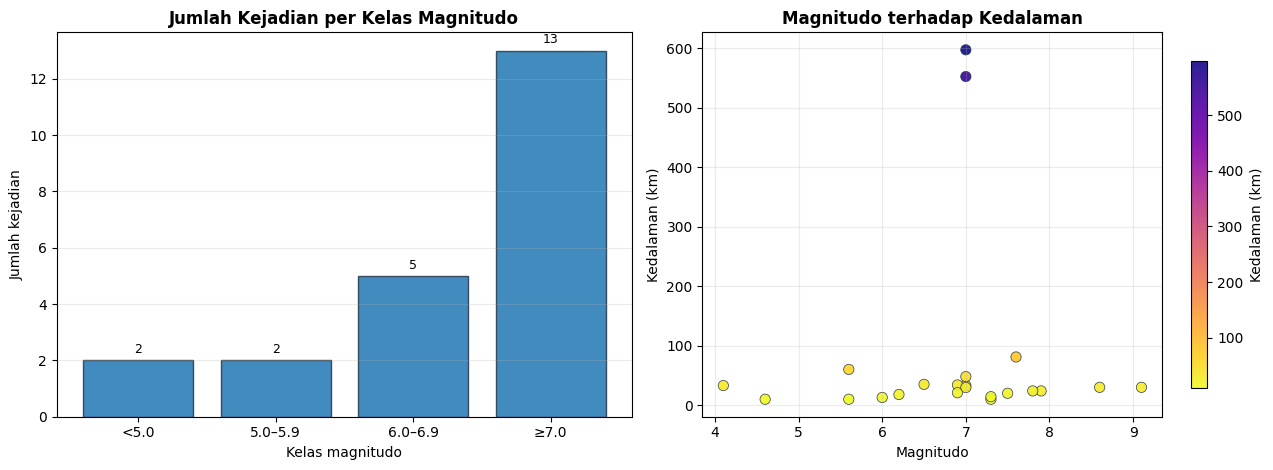

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

counts = df["kelas_magnitudo"].value_counts(sort=False)
axes[0].bar(counts.index.astype(str), counts.values, edgecolor="#263747", alpha=0.85)
axes[0].set_title("Jumlah Kejadian per Kelas Magnitudo", fontweight="bold")
axes[0].set_xlabel("Kelas magnitudo")
axes[0].set_ylabel("Jumlah kejadian")
axes[0].grid(axis="y", alpha=0.25)
for i, count in enumerate(counts.values):
    axes[0].text(i, count + 0.15, str(int(count)), ha="center", va="bottom", fontsize=9)

sc2 = axes[1].scatter(df["mag"], df["depth_km"], s=55, c=df["depth_km"], cmap="plasma_r",
                      edgecolors="#263747", linewidths=0.55, alpha=0.9)
axes[1].set_title("Magnitudo terhadap Kedalaman", fontweight="bold")
axes[1].set_xlabel("Magnitudo")
axes[1].set_ylabel("Kedalaman (km)")
axes[1].grid(alpha=0.25)
fig.colorbar(sc2, ax=axes[1], label="Kedalaman (km)", shrink=0.85)
fig.tight_layout()
fig.savefig(OUT_DIR / "statistik_gempa_indonesia.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Interpretasi 

- Titik episenter pada subset data tersebar di beberapa bagian Indonesia, termasuk Sumatra, Jawa, Nusa Tenggara, Sulawesi, Maluku, dan Papua.
- Simbol paling besar merepresentasikan kejadian dengan magnitudo terbesar pada sampel. Warna memperlihatkan perbedaan kedalaman hiposenter.
- Sebaran yang tampak rapat di sekitar Sulawesi pada data ini sebagian dipengaruhi oleh pilihan event yang dimasukkan; itu **tidak berarti** katalog di sini mencerminkan perbandingan frekuensi semua wilayah secara lengkap.
- Untuk studi kuantitatif, ganti subset dengan katalog API USGS yang dibatasi secara konsisten pada rentang waktu, magnitudo, dan wilayah tertentu. Script `main.py` sudah menyediakan opsi `--update-usgs`.
